In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

from torch.utils.data import DataLoader, random_split

import matplotlib.pyplot as plt
import numpy as np
import random
import os
import csv

# Reproducibility
torch.manual_seed(42)
random.seed(42)
np.random.seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


In [2]:
mean = (0.4914, 0.4822, 0.4465)
std = (0.2470, 0.2435, 0.2616)

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

# Load training dataset
full_train_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

# Recreate the same split as Exercise 2
generator = torch.Generator().manual_seed(42)

train_dataset, val_dataset = random_split(
    full_train_dataset,
    [45000, 5000],
    generator=generator
)

# Load test dataset
test_dataset = torchvision.datasets.CIFAR10(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

# Data loaders
batch_size = 64

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Test images:", len(test_dataset))

Training images: 45000
Validation images: 5000
Test images: 10000


In [3]:
class FlexibleCNN(nn.Module):

    def __init__(self, channels):
        super(FlexibleCNN, self).__init__()

        layers = []
        in_channels = 3

        for i, out_channels in enumerate(channels):

            # Convolutional layer
            layers.append(
                nn.Conv2d(
                    in_channels,
                    out_channels,
                    kernel_size=3,
                    padding=1
                )
            )

            layers.append(nn.ReLU())

            # Apply pooling after every 2 convolutional layers
            if (i + 1) % 2 == 0:
                layers.append(nn.MaxPool2d(kernel_size=2))

            in_channels = out_channels

        self.conv_layers = nn.Sequential(*layers)

        # Reduce feature maps to 1x1
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))

        # Final classification layer
        self.fc = nn.Linear(channels[-1], 10)

    def forward(self, x):

        x = self.conv_layers(x)

        x = self.global_pool(x)

        x = torch.flatten(x, start_dim=1)

        x = self.fc(x)

        return x

In [4]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs.data, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total

    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy


def evaluate(model, data_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs.data, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

    epoch_loss = running_loss / total

    epoch_accuracy = 100 * correct / total

    return epoch_loss, epoch_accuracy

In [5]:
experiments = {
    "Model 1 - Narrow Depth 2": [16, 32],

    "Model 2 - Medium Depth 2": [32, 64],

    "Model 3 - Wide Depth 2": [64, 128],

    "Model 4 - Narrow Depth 3": [16, 32, 64],

    "Model 5 - Medium Depth 3": [32, 64, 128],

    "Model 6 - Narrow Depth 4": [16, 32, 64, 128]
}

In [6]:
def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

In [7]:
results = []

for name, channels in experiments.items():

    print("\n" + "=" * 60)
    print("Training:", name)
    print("Channels:", channels)
    print("=" * 60)

    # Create model
    model = FlexibleCNN(channels).to(device)

    # Count parameters
    parameters = count_parameters(model)

    print("Trainable parameters:", parameters)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001
    )

    # Train for 10 epochs
    for epoch in range(10):

        train_loss, train_accuracy = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            device
        )

        val_loss, val_accuracy = evaluate(
            model,
            val_loader,
            criterion,
            device
        )

        print(
            f"Epoch {epoch + 1}/10 | "
            f"Training Loss: {train_loss:.4f} | "
            f"Training Accuracy: {train_accuracy:.2f}% | "
            f"Validation Accuracy: {val_accuracy:.2f}%"
        )

    # Store final results
    results.append({
        "Model": name,
        "Channels": str(channels),
        "Depth": len(channels),
        "Training Loss": train_loss,
        "Training Accuracy": train_accuracy,
        "Validation Accuracy": val_accuracy,
        "Parameters": parameters
    })

    print("\nFinished:", name)


Training: Model 1 - Narrow Depth 2
Channels: [16, 32]
Trainable parameters: 5418
Epoch 1/10 | Training Loss: 1.9933 | Training Accuracy: 26.34% | Validation Accuracy: 32.72%
Epoch 2/10 | Training Loss: 1.7661 | Training Accuracy: 34.09% | Validation Accuracy: 35.48%
Epoch 3/10 | Training Loss: 1.6976 | Training Accuracy: 37.19% | Validation Accuracy: 38.82%
Epoch 4/10 | Training Loss: 1.6569 | Training Accuracy: 38.95% | Validation Accuracy: 39.24%
Epoch 5/10 | Training Loss: 1.6203 | Training Accuracy: 41.12% | Validation Accuracy: 41.64%
Epoch 6/10 | Training Loss: 1.5856 | Training Accuracy: 42.91% | Validation Accuracy: 43.94%
Epoch 7/10 | Training Loss: 1.5525 | Training Accuracy: 44.56% | Validation Accuracy: 44.62%
Epoch 8/10 | Training Loss: 1.5208 | Training Accuracy: 45.94% | Validation Accuracy: 46.78%
Epoch 9/10 | Training Loss: 1.4955 | Training Accuracy: 47.29% | Validation Accuracy: 46.22%
Epoch 10/10 | Training Loss: 1.4732 | Training Accuracy: 47.92% | Validation Accu

In [8]:
# Create outputs folder if it does not exist
os.makedirs("outputs", exist_ok=True)

# Display results
print(
    f"{'Model':<28}"
    f"{'Depth':<8}"
    f"{'Train Loss':<13}"
    f"{'Train Acc':<13}"
    f"{'Val Acc':<13}"
    f"{'Parameters':<15}"
)

for result in results:

    print(
        f"{result['Model']:<28}"
        f"{result['Depth']:<8}"
        f"{result['Training Loss']:<13.4f}"
        f"{result['Training Accuracy']:<13.2f}"
        f"{result['Validation Accuracy']:<13.2f}"
        f"{result['Parameters']:<15,}"
    )

Model                       Depth   Train Loss   Train Acc    Val Acc      Parameters     
Model 1 - Narrow Depth 2    2       1.4732       47.92        48.24        5,418          
Model 2 - Medium Depth 2    2       1.3460       52.88        52.44        20,042         
Model 3 - Wide Depth 2      2       1.2521       56.13        54.98        76,938         
Model 4 - Narrow Depth 3    3       1.1528       59.53        59.32        24,234         
Model 5 - Medium Depth 3    3       0.9677       66.09        62.54        94,538         
Model 6 - Narrow Depth 4    4       0.8480       70.20        69.04        98,730         


In [9]:
with open(
    "outputs/exercise4_results.csv",
    "w",
    newline=""
) as file:

    writer = csv.DictWriter(
        file,
        fieldnames=results[0].keys()
    )

    writer.writeheader()
    writer.writerows(results)

print("Results saved successfully!")

Results saved successfully!


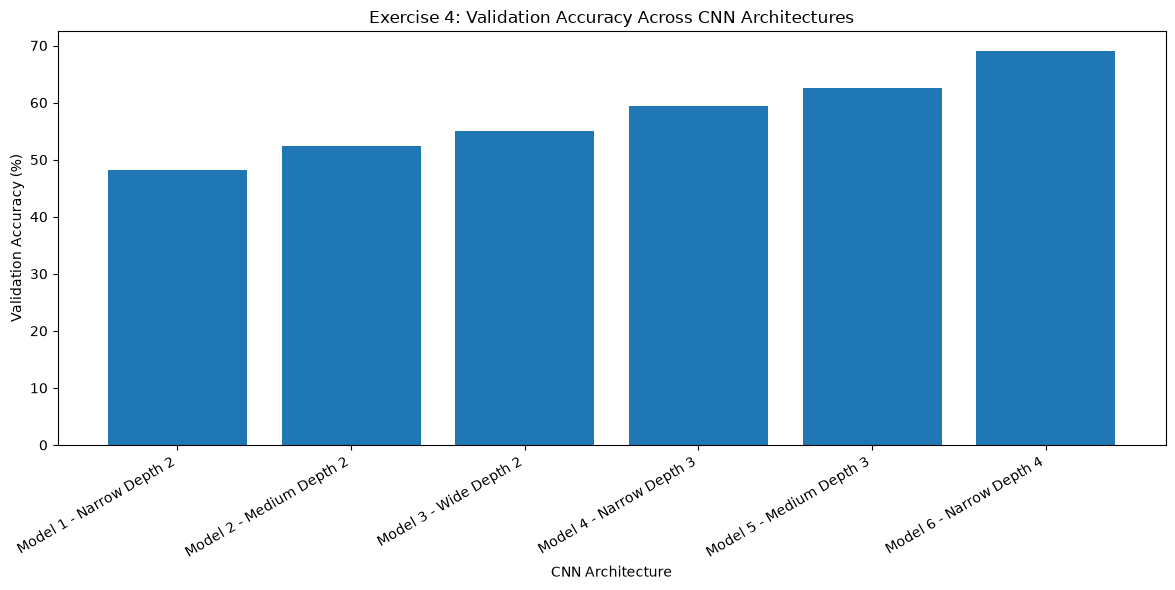

In [10]:
model_names = [r["Model"] for r in results]

validation_accuracies = [
    r["Validation Accuracy"] for r in results
]

plt.figure(figsize=(12, 6))

plt.bar(model_names, validation_accuracies)

plt.xlabel("CNN Architecture")
plt.ylabel("Validation Accuracy (%)")
plt.title("Exercise 4: Validation Accuracy Across CNN Architectures")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.savefig("outputs/exercise4_validation_accuracy.png")

plt.show()

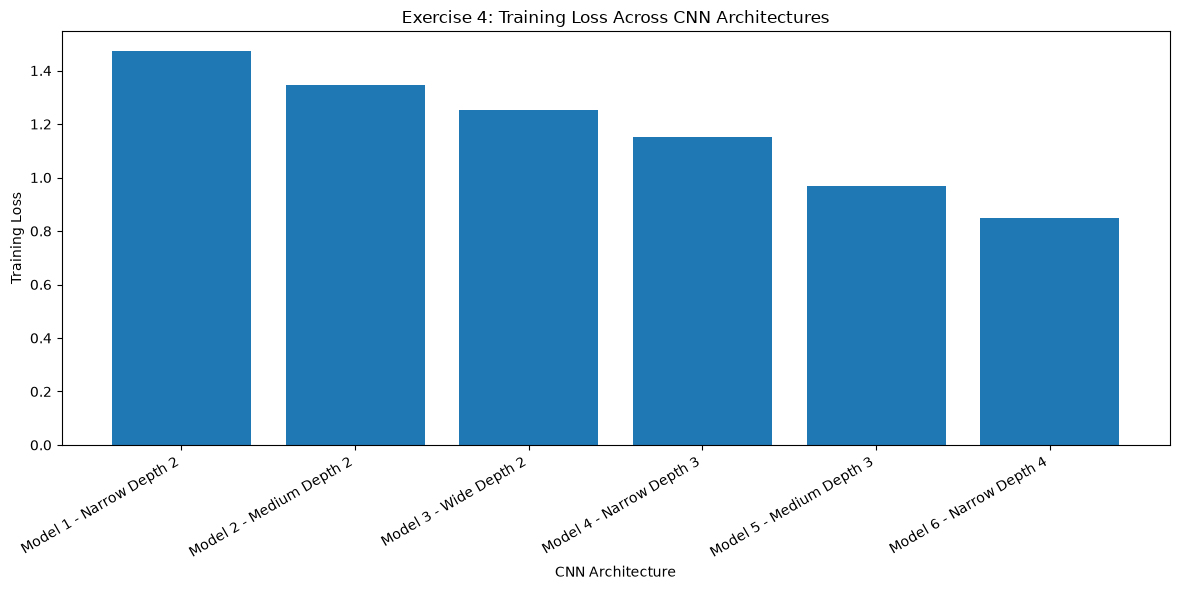

In [11]:
training_losses = [
    r["Training Loss"] for r in results
]

plt.figure(figsize=(12, 6))

plt.bar(model_names, training_losses)

plt.xlabel("CNN Architecture")
plt.ylabel("Training Loss")
plt.title("Exercise 4: Training Loss Across CNN Architectures")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.savefig("outputs/exercise4_training_loss.png")

plt.show()

In [ ]:
print("FINAL MLP RESULTS")
print("-------------------------")

print(f"Training Loss: {history['train_loss'][-1]:.4f}")
print(f"Validation Loss: {history['val_loss'][-1]:.4f}")
print(f"Validation Accuracy: {history['val_accuracy'][-1]:.2f}%")

print(f"Training Accuracy: {history['train_accuracy'][-1]:.2f}%")
print(f"Test Accuracy: {history['test_accuracy'][-1]:.2f}%")

FINAL MLP RESULTS
-------------------------
Training Loss: 0.9005
Validation Loss: 1.5575
Validation Accuracy: 51.16%
Training Accuracy: 67.88%
Test Accuracy: 52.71%


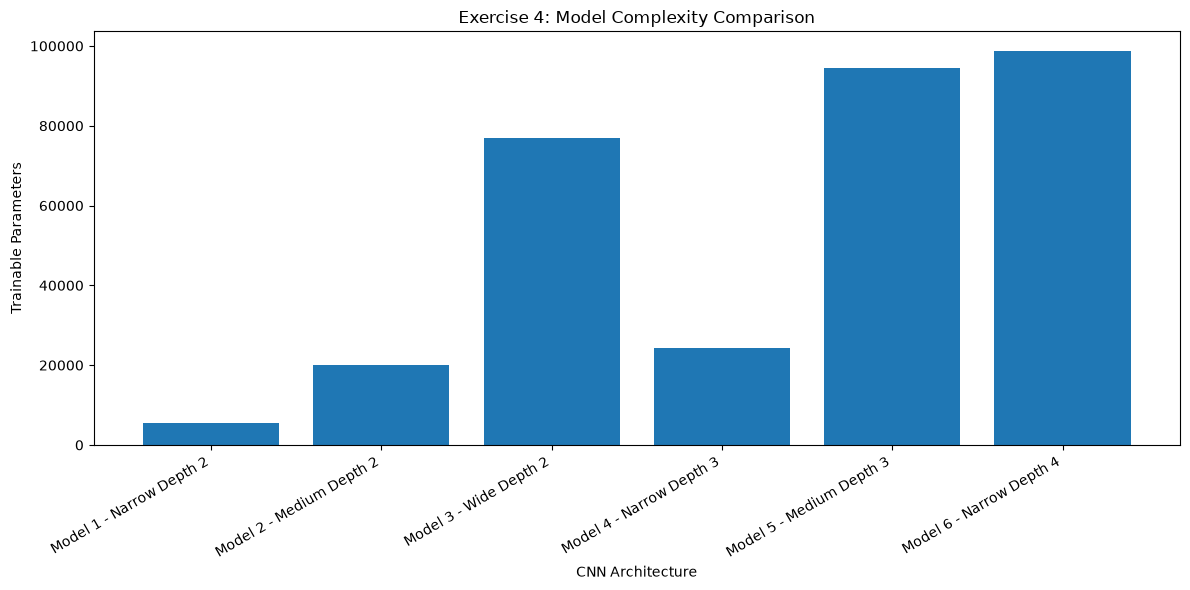

In [12]:
parameter_counts = [
    r["Parameters"] for r in results
]

plt.figure(figsize=(12, 6))

plt.bar(model_names, parameter_counts)

plt.xlabel("CNN Architecture")
plt.ylabel("Trainable Parameters")
plt.title("Exercise 4: Model Complexity Comparison")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()

plt.savefig("outputs/exercise4_parameters.png")

plt.show()

## Exercise 4: Model Width and Depth

### 1. Effect of Width on CNN Performance

The first experiment investigated how increasing the width of a CNN affects its performance while keeping the convolutional depth at two layers.

Three configurations were tested: 16–32, 32–64 and 64–128 channels.

The narrow CNN achieved a validation accuracy of 48.24%, while the medium-width CNN achieved 52.44%. The wide CNN achieved the highest validation accuracy among these three models, at 54.98%.

This demonstrates that increasing the number of channels improved classification performance. Wider convolutional layers can learn a greater variety of visual features from images, which can help the network distinguish between different CIFAR-10 classes.

However, increasing width also increased model complexity. The number of trainable parameters increased from 5,418 in the narrow model to 76,938 in the wide model. Therefore, wider architectures required substantially more trainable parameters to achieve their performance improvements.

### 2. Effect of Depth on CNN Performance

The second experiment investigated how increasing the number of convolutional layers affected performance.

The two-layer CNN achieved a validation accuracy of 48.24%. Increasing the depth to three convolutional layers improved validation accuracy to 59.32%. Adding a fourth convolutional layer further increased validation accuracy to 69.04%.

The four-layer CNN achieved the best validation accuracy across all six experiments.

This suggests that increasing network depth was particularly effective in this experiment. Deeper CNNs can learn hierarchical image features, beginning with simpler patterns such as edges and textures and progressing towards more complex visual patterns.

The results demonstrate that adding convolutional layers improved the model's ability to classify CIFAR-10 images.

### 3. Model Complexity and Training Behaviour

The experiments showed that increasing width and depth generally increased the number of trainable parameters.

Model 1 contained 5,418 trainable parameters, whereas Model 6 contained 98,730 parameters. This represents a substantial increase in model complexity.

Training loss also decreased as the architectures became larger and deeper. Model 1 achieved a training loss of 1.4732, while Model 6 achieved the lowest training loss of 0.8480.

Training accuracy increased from 47.92% in Model 1 to 70.20% in Model 6. This indicates that the more complex architectures learned the training data more effectively.

### 4. Overfitting and Generalisation

The difference between training and validation accuracy was relatively small across the experiments.

For example, Model 1 achieved 47.92% training accuracy and 48.24% validation accuracy. Model 6 achieved 70.20% training accuracy and 69.04% validation accuracy.

The difference between training and validation accuracy for Model 6 was only 1.16 percentage points.

Although Model 5 showed a larger difference of 3.55 percentage points, none of the six models showed a particularly large training-validation gap in these results.

This suggests that the increased model complexity did not produce substantial overfitting during these experiments. However, training and validation performance alone cannot establish how well a model performs on a completely unseen test dataset.

### 5. Conclusion

Overall, the experiments demonstrated that both increasing CNN width and increasing CNN depth improved validation accuracy.

Increasing width improved the performance of the two-layer CNNs, although the improvement became smaller as the number of channels increased.

Increasing depth produced a stronger improvement in this experiment. The four-layer CNN achieved the highest validation accuracy of 69.04%, together with the lowest training loss of 0.8480.

Although the deeper models required more trainable parameters, their improvements in validation accuracy suggest that the additional model complexity was beneficial for this CIFAR-10 classification task.

Therefore, Model 6, with four convolutional layers and channel configuration 16–32–64–128, was the best-performing architecture among the six models tested.